# 04 · Model training and comparison (5 models)

**Input:** `data/features/{train,student_test}.parquet` from notebook 03.
**Output:** `outputs/models/` (comparison + per-fold CSVs, configs, experiment log, figures, `MODEL_COMPARISON.md`)
and the fitted models in `models/`.

**Task:** each row is a (GPS fix, candidate arc) pair; predict P(candidate is the true arc). At prediction time each
fix takes its highest-probability candidate (**Top-1**). The models, preprocessing and metric code are in
`src/pathsnap/training.py`.

| # | model | family | why it is in the comparison |
|---|---|---|---|
| 1 | Logistic Regression | Linear | simple baseline with clean probabilities; fast and easy to explain |
| 2 | K-Nearest Neighbours | Instance-based | decides by looking at similar past examples; slow on big data, so trained on a documented sample |
| 3 | Random Forest | Ensemble (bagging) | non-linear, stable, and shows which features matter |
| 4 | LightGBM | Boosting | usually the strongest on tabular data, and fast |
| 5 | MLP | Neural network | gives real epoch-by-epoch training and validation loss curves |

**Protocol**
* **5-fold GroupKFold on `trip_id`** over the 80 train trips (shuffled, seed 42). A trip is never split across train and validation,
  because neighbouring fixes are near-duplicates.
* **Training rows** = `label_reliable` rows of non-excluded trips (trips 33 and 54 are excluded by the cleaning step).
  Route-derived columns are never inputs.
* Scaling (log1p on heavy-tailed features, then StandardScaler) is inside each model's Pipeline, so it is fitted on the
  training fold only. Trees use the raw features.
* After CV, every model is **refit on all usable train trips** and scored **once** on the 10 student_test trips.
  student_test is used only for this final comparison, never to choose settings.
* Metrics are reported on **all** labelled fixes (of non-excluded trips) and on **label-reliable** fixes only.

In [1]:
import json, sys, time
from pathlib import Path
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pathsnap import training as T
from pathsnap.features import FEATURE_COLS
from pathsnap.cleaning import PROCESSED_ROOT

OUT, MODELS = ROOT / "outputs" / "models", ROOT / "models"
FIG = OUT / "figures"
for d in (OUT, FIG, MODELS):
    d.mkdir(parents=True, exist_ok=True)
LOG = OUT / "experiment_log.jsonl"
LOG.write_text("")                                     # one fresh log per full run

def log(event, **kw):
    with LOG.open("a") as f:
        f.write(json.dumps({"time": datetime.now(timezone.utc).isoformat(timespec="seconds"), "event": event, **kw}) + "\n")

train = pd.read_parquet(ROOT / "data" / "features" / "train.parquet")
test = pd.read_parquet(ROOT / "data" / "features" / "student_test.parquet")
train_fx = pd.read_parquet(ROOT / "data" / "features" / "train_fixes.parquet")
test_fx = pd.read_parquet(ROOT / "data" / "features" / "student_test_fixes.parquet")

def load_arcs(part):
    out = {}
    for d in (PROCESSED_ROOT / part).iterdir():
        a = pd.read_csv(d / "arcs.csv.gz", usecols=["from_node", "to_node"])
        out[d.name] = (a.from_node.to_numpy(), a.to_node.to_numpy())
    return out
arcs = {**load_arcs("train"), **load_arcs("student_test")}   # trip ids are unique across partitions

specs = T.model_specs()
MODEL_COLORS = dict(zip(specs, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))  # fixed per model
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d9d8d2", "grid.linewidth": 0.6, "figure.dpi": 110})
print(f"train: {len(train):,} rows, {T.training_mask(train).sum():,} usable for training; "
      f"student_test: {len(test):,} rows; {len(FEATURE_COLS)} features")

train: 1,530,256 rows, 1,430,632 usable for training; student_test: 169,234 rows; 27 features


In [2]:
configs = {
    "seed": T.SEED, "n_folds": T.N_FOLDS, "cv": "GroupKFold(shuffle=True) on trip_id, 80 train trips",
    "training_rows": "label_reliable & ~exclude_trip", "features": FEATURE_COLS, "log1p_columns": T.SKEWED,
    "candidates": json.loads((ROOT / "outputs" / "features" / "candidate_config.json").read_text()),
    "models": {n: {"family": s.family, "params": s.config, "preprocessing": s.notes,
                   "train_sample_rows": s.sample_rows} for n, s in specs.items()},
}
(OUT / "configs.json").write_text(json.dumps(configs, indent=1))
pd.DataFrame({n: {"family": s.family, "preprocessing": s.notes, "params": json.dumps(s.config)} for n, s in specs.items()}).T

,family,preprocessing,params
LogisticRegression,Linear,log1p + StandardScaler,"{""C"": 1.0, ""solver"": ""lbfgs"", ""max_iter"": 1000}"
KNN,Instance-based,log1p + StandardScaler; trained on a random 15...,"{""n_neighbors"": 50, ""weights"": ""uniform"", ""alg..."
RandomForest,Ensemble (bagging),raw features (trees do not need scaling),"{""n_estimators"": 150, ""max_features"": ""sqrt"", ..."
LightGBM,Boosting,raw features,"{""n_estimators"": 400, ""learning_rate"": 0.05, ""..."
MLP,Neural network,log1p + StandardScaler; trained with partial_f...,"{""hidden_layer_sizes"": [64, 32], ""activation"":..."


## 1. Cross-validation on the 80 train trips
For each fold: fit on the training rows of the training trips, then predict **every** candidate row of the validation
trips and score them. The MLP also records train and validation log loss after every epoch.

In [3]:
gkf = GroupKFold(n_splits=T.N_FOLDS, shuffle=True, random_state=T.SEED)
trips = train.trip_id.to_numpy()
folds = list(gkf.split(train, groups=trips))
pd.DataFrame([{"fold": k, "train_trips": len(np.unique(trips[a])), "val_trips": len(np.unique(trips[b])),
               "val_trip_ids": " ".join(sorted(np.unique(trips[b])))} for k, (a, b) in enumerate(folds)])

,fold,train_trips,val_trips,val_trip_ids
0,0,64,16,00000001 00000005 00000013 00000016 00000024 0...
1,1,64,16,00000006 00000012 00000021 00000042 00000047 0...
2,2,64,16,00000004 00000008 00000010 00000011 00000018 0...
3,3,64,16,00000014 00000020 00000031 00000033 00000034 0...
4,4,64,16,00000002 00000003 00000019 00000026 00000027 0...


In [4]:
per_fold, histories = [], []
usable = T.training_mask(train)
t_cv = time.perf_counter()
for name, spec in specs.items():
    for k, (tr_idx, va_idx) in enumerate(folds):
        tr_rows = train.iloc[tr_idx][usable[tr_idx]]
        va_rows = train.iloc[va_idx]
        va_trips = set(va_rows.trip_id)
        model, fit_s, hist = T.fit_model(spec, tr_rows, rows_val=va_rows[T.training_mask(va_rows)])
        p, pred_s = T.predict(model, va_rows)
        m = T.evaluate(va_rows, train_fx[train_fx.trip_id.isin(va_trips)], p, arcs)
        rec = {"model": name, "fold": k, "fit_s": fit_s, "predict_s": pred_s, "train_rows": len(tr_rows),
               **{key: v for key, v in m.items() if not key.endswith("_cm")}}
        per_fold.append(rec)
        histories += [{"model": name, "fold": k, **h} for h in hist]
        log("cv_fold", **rec)
        print(f"{name:18s} fold {k}: top1(rel) {m['reliable_top1']:.4f}  macroF1 {m['all_macro_f1']:.4f}  "
              f"logloss {m['all_logloss']:.4f}  fit {fit_s:.0f}s")
per_fold = pd.DataFrame(per_fold)
per_fold.to_csv(OUT / "per_fold.csv", index=False)
print(f"CV done in {(time.perf_counter() - t_cv) / 60:.1f} min")

LogisticRegression fold 0: top1(rel) 0.8590  macroF1 0.9088  logloss 0.1173  fit 4s


LogisticRegression fold 1: top1(rel) 0.9150  macroF1 0.9410  logloss 0.0846  fit 7s


LogisticRegression fold 2: top1(rel) 0.8629  macroF1 0.9074  logloss 0.1026  fit 4s


LogisticRegression fold 3: top1(rel) 0.9218  macroF1 0.9480  logloss 0.0660  fit 4s


LogisticRegression fold 4: top1(rel) 0.8507  macroF1 0.9072  logloss 0.1012  fit 4s


KNN                fold 0: top1(rel) 0.8492  macroF1 0.9058  logloss 0.1191  fit 0s


... (15 outputs left out)

MLP                fold 1: top1(rel) 0.9130  macroF1 0.9482  logloss 0.0626  fit 103s


MLP                fold 2: top1(rel) 0.8535  macroF1 0.9110  logloss 0.1129  fit 104s


MLP                fold 3: top1(rel) 0.9314  macroF1 0.9557  logloss 0.0500  fit 224s


MLP                fold 4: top1(rel) 0.8542  macroF1 0.9135  logloss 0.0866  fit 104s
CV done in 24.0 min


In [5]:
METRICS = ["all_macro_f1", "all_top1", "reliable_top1", "reliable_macro_f1", "all_logloss", "route_continuity"]
cv = per_fold.groupby("model", sort=False)[METRICS + ["fit_s"]].agg(["mean", "std"])
cv.round(4)

all_macro_f1         all_top1         reliable_top1  \
                           mean     std     mean     std          mean   
model                                                                    
LogisticRegression       0.9225  0.0203   0.8778  0.0369        0.8819   
KNN                      0.9200  0.0201   0.8733  0.0374        0.8773   
RandomForest             0.9342  0.0203   0.8871  0.0372        0.8912   
LightGBM                 0.9328  0.0212   0.8851  0.0379        0.8892   
MLP                      0.9295  0.0209   0.8793  0.0390        0.8833   

                           reliable_macro_f1         all_logloss          \
                       std              mean     std        mean     std   
model                                                                      
LogisticRegression  0.0337            0.9232  0.0197      0.0944  0.0196   
KNN                 0.0338            0.9203  0.0199      0.0962  0.0233   
RandomForest        0.0334            0.9347  0.0199      0.0695  0.0178   
LightGBM            0.0342            0.9332  0.0210      0.0703  0.0202   
MLP                 0.0364            0.9298  0.0209      0.0846  0.0282   

                   route_continuity             fit_s           
                               mean     std      mean      std  
model                                                           
LogisticRegression           0.9426  0.0209    4.5328   1.3069  
KNN                          0.9492  0.0182    0.1453   0.0628  
RandomForest                 0.9557  0.0147   60.7194  27.8430  
LightGBM                     0.9581  0.0148   12.3432   1.7803  
MLP                          0.9542  0.0190  139.2616  53.4609

### MLP loss curves (real per-epoch values)
Train loss is measured on a fixed 200k-row sample of the training fold; validation loss on the validation fold's
training-type rows. The number of epochs for the final refit is the epoch with the lowest **mean CV validation loss**,
so it is chosen without looking at student_test.

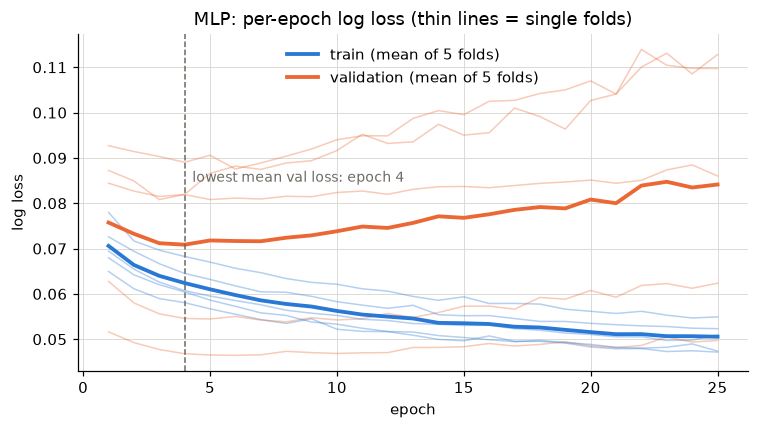

MLP epochs for the final refit: 4


2639

In [6]:
hist = pd.DataFrame(histories)
hist.to_csv(OUT / "mlp_history.csv", index=False)
mean_val = hist.groupby("epoch").val_logloss.mean()
best_epoch = int(mean_val.idxmin())
fig, ax = plt.subplots(figsize=(7, 4))
for k, g in hist.groupby("fold"):
    ax.plot(g.epoch, g.train_logloss, color="#2a78d6", lw=1, alpha=0.35)
    ax.plot(g.epoch, g.val_logloss, color="#eb6834", lw=1, alpha=0.35)
ax.plot(mean_val.index, hist.groupby("epoch").train_logloss.mean(), color="#2a78d6", lw=2.5, label="train (mean of 5 folds)")
ax.plot(mean_val.index, mean_val, color="#eb6834", lw=2.5, label="validation (mean of 5 folds)")
ax.axvline(best_epoch, color="#6b6a63", lw=1, ls="--")
ax.annotate(f"lowest mean val loss: epoch {best_epoch}", (best_epoch, mean_val.max()), xytext=(5, 0),
            textcoords="offset points", fontsize=9, color="#6b6a63")
ax.set_xlabel("epoch"); ax.set_ylabel("log loss"); ax.set_title("MLP: per-epoch log loss (thin lines = single folds)")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "mlp_loss_curves.png"); plt.show()
print("MLP epochs for the final refit:", best_epoch)
configs["models"]["MLP"]["final_epochs"] = best_epoch
(OUT / "configs.json").write_text(json.dumps(configs, indent=1))

## 2. Refit on all usable train trips, then score once on student_test
Inference time = `predict_proba` over all student_test candidate rows, reported per 1,000 GPS fixes. Feature
extraction is the same for every model, so it is not included.

In [7]:
final, cms, test_preds = [], {}, {}
tr_rows = train[usable]
for name, spec in specs.items():
    model, fit_s, _ = T.fit_model(spec, tr_rows, epochs=best_epoch if spec.epochs else None)
    p, pred_s = T.predict(model, test)
    m = T.evaluate(test, test_fx, p, arcs)
    cms[name] = {"all": m["all_cm"], "reliable": m["reliable_cm"]}
    test_preds[name] = p
    path = MODELS / f"{name}.joblib"
    joblib.dump(model, path, compress=3)
    rec = {"model": name, "fit_s": fit_s, "predict_s": pred_s,
           "infer_ms_per_1k_fixes": 1000 * pred_s / len(test_fx) * 1000,
           "model_file_mb": path.stat().st_size / 1e6,
           **{k: v for k, v in m.items() if not k.endswith("_cm")}}
    final.append(rec)
    log("final_fit", **rec)
    print(f"{name:18s} student_test top1(all) {m['all_top1']:.4f}  top1(rel) {m['reliable_top1']:.4f}  "
          f"macroF1 {m['all_macro_f1']:.4f}  fit {fit_s:.0f}s  file {rec['model_file_mb']:.1f} MB")
final = pd.DataFrame(final).set_index("model")
(OUT / "confusion_matrices.json").write_text(json.dumps(cms, indent=1))
pd.DataFrame({"trip_id": test.trip_id, "fix_idx": test.fix_idx, "arc_id": test.arc_id, "label": test.label,
              **{f"p_{n}": p for n, p in test_preds.items()}}).to_parquet(OUT / "student_test_probs.parquet", index=False)

LogisticRegression student_test top1(all) 0.8772  top1(rel) 0.8783  macroF1 0.9230  fit 5s  file 0.0 MB


KNN                student_test top1(all) 0.8779  top1(rel) 0.8790  macroF1 0.9202  fit 0s  file 17.5 MB


RandomForest       student_test top1(all) 0.9001  top1(rel) 0.9012  macroF1 0.9395  fit 93s  file 17.8 MB


LightGBM           student_test top1(all) 0.8943  top1(rel) 0.8955  macroF1 0.9352  fit 29s  file 1.3 MB


MLP                student_test top1(all) 0.8860  top1(rel) 0.8871  macroF1 0.9314  fit 21s  file 0.1 MB


## 3. Comparison table

In [8]:
rows = []
for name, spec in specs.items():
    cvm, f = cv.loc[name], final.loc[name]
    rows.append({
        "model": name, "family": spec.family, "key config": spec.notes + "; " + ", ".join(f"{k}={v}" for k, v in spec.config.items() if k not in ("n_jobs", "verbose")),
        "CV macro F1": f"{cvm[('all_macro_f1', 'mean')]:.4f} ± {cvm[('all_macro_f1', 'std')]:.4f}",
        "CV Top-1 (all)": f"{cvm[('all_top1', 'mean')]:.4f} ± {cvm[('all_top1', 'std')]:.4f}",
        "CV Top-1 (reliable)": f"{cvm[('reliable_top1', 'mean')]:.4f} ± {cvm[('reliable_top1', 'std')]:.4f}",
        "CV log loss": f"{cvm[('all_logloss', 'mean')]:.4f} ± {cvm[('all_logloss', 'std')]:.4f}",
        "ST Top-1 (all)": round(f.all_top1, 4), "ST Top-1 (reliable)": round(f.reliable_top1, 4),
        "ST macro F1 (all)": round(f.all_macro_f1, 4), "ST macro F1 (reliable)": round(f.reliable_macro_f1, 4),
        "ST precision": round(f.all_precision, 4), "ST recall": round(f.all_recall, 4),
        "ST log loss (all)": round(f.all_logloss, 4), "ST log loss (reliable)": round(f.reliable_logloss, 4),
        "ST route continuity": round(f.route_continuity, 4), "ST miss rate (all)": round(f.all_miss_rate, 5),
        "train time (s)": round(f.fit_s, 1), "inference ms / 1k fixes": round(f.infer_ms_per_1k_fixes, 1),
        "model file (MB)": round(f.model_file_mb, 1),
    })
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(OUT / "model_comparison.csv")
comparison.drop(columns=["key config"]).T

model,LogisticRegression,KNN,RandomForest,LightGBM,MLP
family,Linear,Instance-based,Ensemble (bagging),Boosting,Neural network
CV macro F1,0.9225 ± 0.0203,0.9200 ± 0.0201,0.9342 ± 0.0203,0.9328 ± 0.0212,0.9295 ± 0.0209
CV Top-1 (all),0.8778 ± 0.0369,0.8733 ± 0.0374,0.8871 ± 0.0372,0.8851 ± 0.0379,0.8793 ± 0.0390
CV Top-1 (reliable),0.8819 ± 0.0337,0.8773 ± 0.0338,0.8912 ± 0.0334,0.8892 ± 0.0342,0.8833 ± 0.0364
CV log loss,0.0944 ± 0.0196,0.0962 ± 0.0233,0.0695 ± 0.0178,0.0703 ± 0.0202,0.0846 ± 0.0282
ST Top-1 (all),0.8772,0.8779,0.9001,0.8943,0.886
ST Top-1 (reliable),0.8783,0.879,0.9012,0.8955,0.8871
ST macro F1 (all),0.923,0.9202,0.9395,0.9352,0.9314
ST macro F1 (reliable),0.9233,0.9206,0.9398,0.9355,0.9317
ST precision,0.8554,0.8563,0.9082,0.899,0.8997


Route continuity for comparison: the reference labels themselves are not 100 % continuous (route breaks, and the
alignment can jump). The value for the true labels is computed below with the same function.

In [9]:
ref = test_fx[test_fx.has_label][["trip_id", "fix_idx", "segment_id", "true_arc"]].rename(columns={"true_arc": "pred_arc"})
ref_cont = T.route_continuity(ref, arcs)
print(f"route continuity of the reference labels on student_test: {ref_cont:.4f}")

route continuity of the reference labels on student_test: 0.9849


## 4. Figures

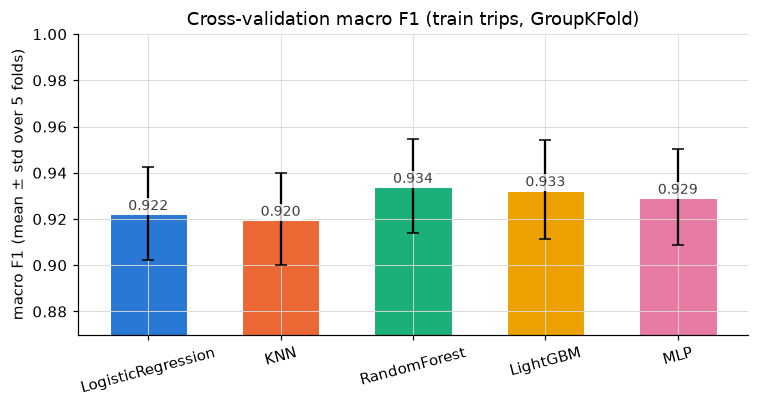

In [10]:
names = list(specs)
cols = [MODEL_COLORS[n] for n in names]

def bars(ax, vals, errs=None, fmt="{:.3f}"):
    x = np.arange(len(names))
    ax.bar(x, vals, 0.6, yerr=errs, color=cols, capsize=4, edgecolor="white", linewidth=2)
    for xi, v in zip(x, vals):
        ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=9, color="#3d3d3a",
                bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.8))
    ax.set_xticks(x, names, rotation=15)

fig, ax = plt.subplots(figsize=(7, 3.8))
bars(ax, cv[("all_macro_f1", "mean")].values, cv[("all_macro_f1", "std")].values)
lo = cv[("all_macro_f1", "mean")].min() - 0.05
ax.set_ylim(lo, 1); ax.set_ylabel("macro F1 (mean ± std over 5 folds)")
ax.set_title("Cross-validation macro F1 (train trips, GroupKFold)")
fig.tight_layout(); fig.savefig(FIG / "cv_macro_f1.png"); plt.show()

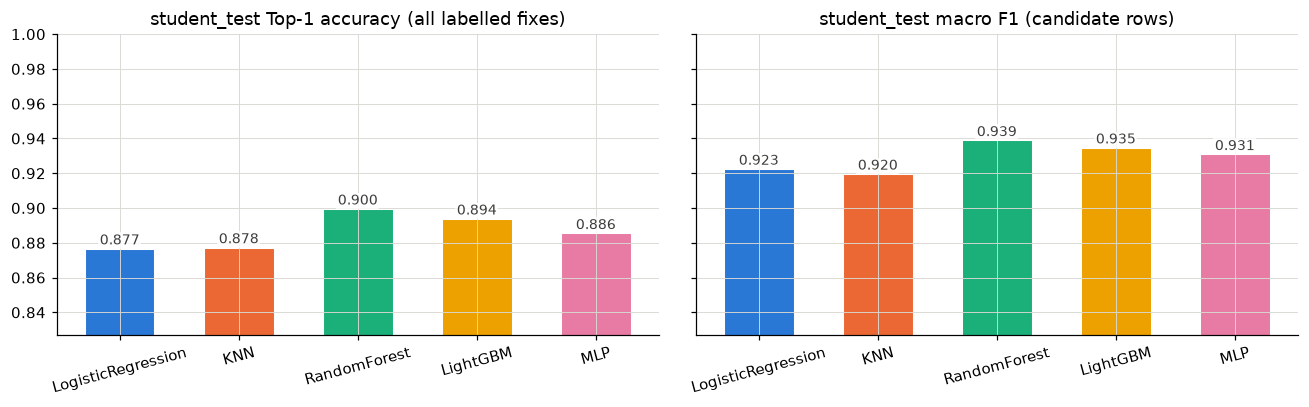

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (col, title) in zip(axes, [("all_top1", "student_test Top-1 accuracy (all labelled fixes)"),
                                   ("all_macro_f1", "student_test macro F1 (candidate rows)")]):
    bars(ax, final.loc[names, col].values)
    ax.set_title(title)
lo = min(final.all_top1.min(), final.all_macro_f1.min()) - 0.05
axes[0].set_ylim(lo, 1)
fig.tight_layout(); fig.savefig(FIG / "student_test_top1_macro_f1.png"); plt.show()

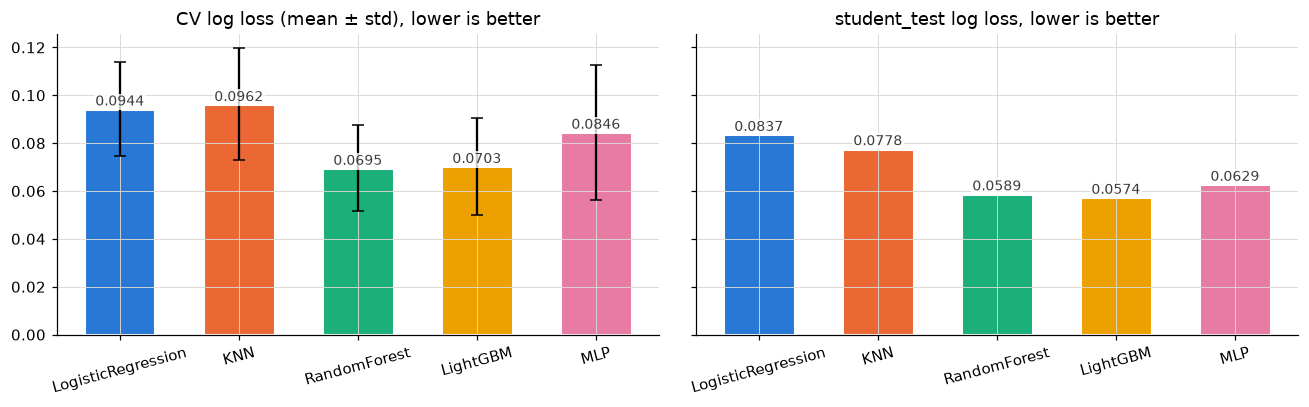

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bars(axes[0], cv[("all_logloss", "mean")].values, cv[("all_logloss", "std")].values, fmt="{:.4f}")
axes[0].set_title("CV log loss (mean ± std), lower is better")
bars(axes[1], final.loc[names, "all_logloss"].values, fmt="{:.4f}")
axes[1].set_title("student_test log loss, lower is better")
fig.tight_layout(); fig.savefig(FIG / "log_loss.png"); plt.show()

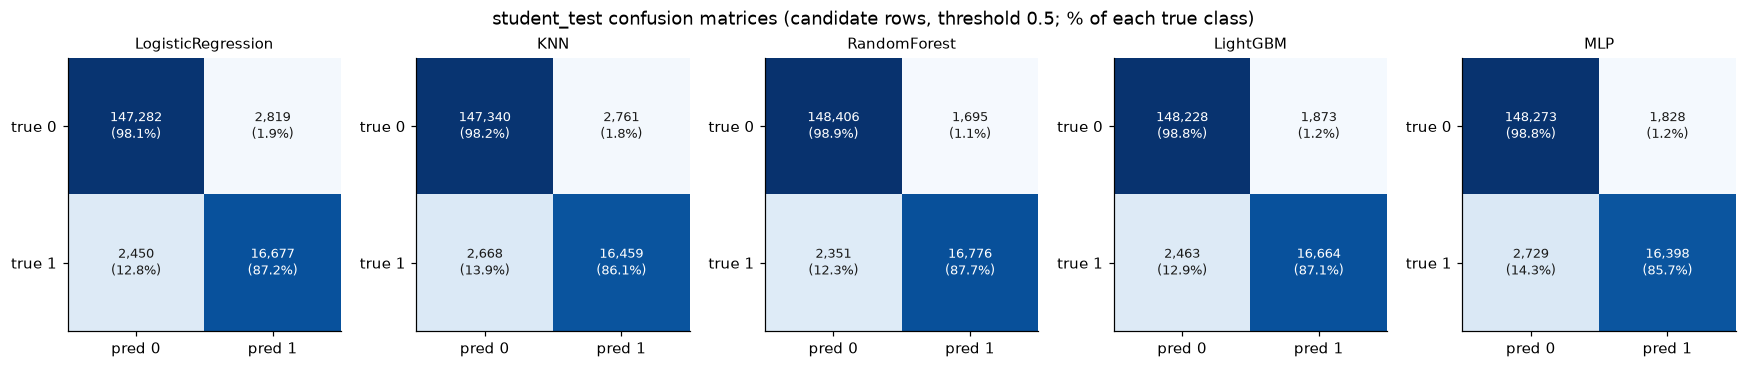

In [13]:
fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 3.2))
for ax, n in zip(axes, names):
    cm = np.array(cms[n]["all"])
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({norm[i, j]:.1%})", ha="center", va="center", fontsize=8.5,
                    color="white" if norm[i, j] > 0.5 else "#1a1a19")
    ax.set_xticks([0, 1], ["pred 0", "pred 1"]); ax.set_yticks([0, 1], ["true 0", "true 1"])
    ax.set_title(n, fontsize=10); ax.grid(False)
fig.suptitle("student_test confusion matrices (candidate rows, threshold 0.5; % of each true class)")
fig.tight_layout(); fig.savefig(FIG / "confusion_matrices.png"); plt.show()

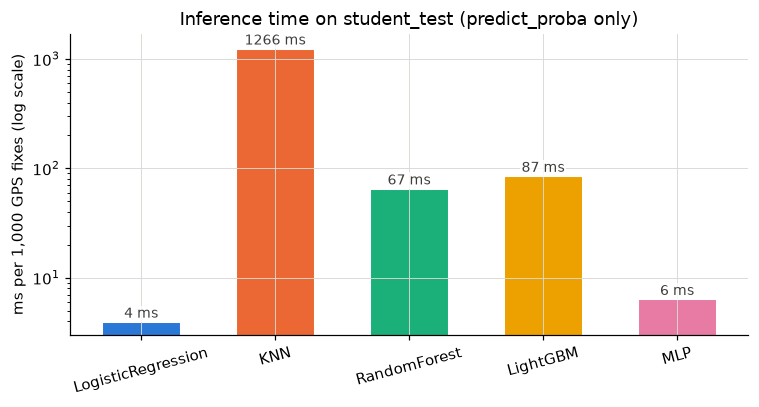

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
bars(ax, final.loc[names, "infer_ms_per_1k_fixes"].values, fmt="{:.0f} ms")
ax.set_yscale("log"); ax.set_ylabel("ms per 1,000 GPS fixes (log scale)")
ax.set_title("Inference time on student_test (predict_proba only)")
fig.tight_layout(); fig.savefig(FIG / "inference_time.png"); plt.show()

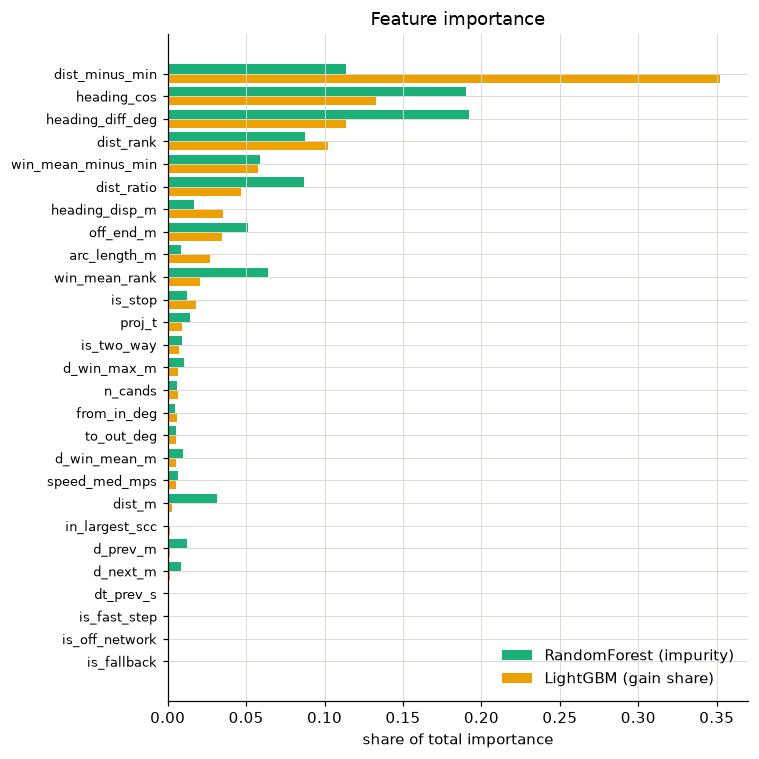

,RandomForest (impurity),LightGBM (gain share)
dist_minus_min,0.114,0.352
heading_cos,0.190,0.133
heading_diff_deg,0.192,0.114
dist_rank,0.088,0.102
win_mean_minus_min,0.059,0.058
dist_ratio,0.087,0.047
heading_disp_m,0.017,0.035
off_end_m,0.051,0.034
arc_length_m,0.008,0.027
win_mean_rank,0.064,0.021


In [15]:
rf = joblib.load(MODELS / "RandomForest.joblib")
lgb = joblib.load(MODELS / "LightGBM.joblib")
imp = pd.DataFrame({"RandomForest (impurity)": rf.feature_importances_,
                    "LightGBM (gain share)": lgb.booster_.feature_importance("gain") / lgb.booster_.feature_importance("gain").sum()},
                   index=FEATURE_COLS).sort_values("LightGBM (gain share)")
fig, ax = plt.subplots(figsize=(7, 7))
y = np.arange(len(imp)); h = 0.4
ax.barh(y + h / 2, imp.iloc[:, 0], h, color=MODEL_COLORS["RandomForest"], label=imp.columns[0])
ax.barh(y - h / 2, imp.iloc[:, 1], h, color=MODEL_COLORS["LightGBM"], label=imp.columns[1])
ax.set_yticks(y, imp.index, fontsize=8.5); ax.set_xlabel("share of total importance")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Feature importance")
fig.tight_layout(); fig.savefig(FIG / "feature_importance.png"); plt.show()
imp.sort_values("LightGBM (gain share)", ascending=False).head(10).round(3)

## 5. Write `MODEL_COMPARISON.md`

In [16]:
cv_tab = pd.DataFrame({n: {m: f"{cv.loc[n, (m, 'mean')]:.4f} ± {cv.loc[n, (m, 'std')]:.4f}" for m in METRICS + ['fit_s']}
                       for n in names}).T
main_cols = ["family", "CV macro F1", "CV Top-1 (all)", "ST Top-1 (all)", "ST Top-1 (reliable)", "ST macro F1 (all)",
             "ST log loss (all)", "ST route continuity", "inference ms / 1k fixes"]
detail_cols = ["ST precision", "ST recall", "ST macro F1 (reliable)", "ST log loss (reliable)", "ST miss rate (all)",
               "train time (s)", "model file (MB)"]
Lm = ["# PathSnap: Model Comparison (step 4)", "",
      "Auto-generated by `notebooks/04_model_training.ipynb`. Every number comes from that run (seed 42).", "",
      "* CV = 5-fold GroupKFold on trip_id over the 80 train trips (mean ± std over folds).",
      "* ST = student_test (10 trips), scored once after refitting on all usable train trips.",
      "* Top-1 = share of GPS fixes whose highest-probability candidate is the true arc (a fix whose true arc is not "
      "a candidate counts as wrong). Macro F1 / precision / recall / log loss are on candidate rows at threshold 0.5.",
      "* all = labelled fixes of non-excluded trips; reliable = label_reliable fixes only.",
      f"* Route continuity = share of consecutive fix pairs whose predicted arcs are the same or connected "
      f"(reference labels: {ref_cont:.4f}).", "",
      "## Main table", "", comparison[main_cols].to_markdown(), "",
      "## More student_test detail", "", comparison[detail_cols].to_markdown(), "",
      "## Cross-validation (mean ± std over 5 folds)", "", cv_tab.to_markdown(), "",
      "## Configurations", "", comparison[["family", "key config"]].to_markdown(), "",
      f"MLP final epochs = {best_epoch} (lowest mean CV validation loss). Full configs: `configs.json`; per-fold "
      "results: `per_fold.csv`; log: `experiment_log.jsonl`.", "",
      "## Figures", "", *[f"![{p.stem}](figures/{p.name})" for p in sorted(FIG.glob("*.png"))], ""]
(OUT / "MODEL_COMPARISON.md").write_text("\n".join(Lm), encoding="utf-8")
print("wrote", OUT / "MODEL_COMPARISON.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\models\MODEL_COMPARISON.md


## 6. Discussion (written after reading this run's results)

* **All five models clearly beat the no-model baseline.** Picking the nearest arc gets 51–55 % Top-1; every model gets
  0.87–0.90 on student_test. Most of the gain comes from the heading and window-consistency features, which separate
  the two directions of a two-way street (see `feature_importance.png`).
* **Random Forest has the best accuracy, but only just.** CV Top-1 is 0.8871 vs 0.8851 for LightGBM, and RF is ahead
  in all 5 folds by 0.02–0.50 percentage points. On student_test it is 0.9001 vs 0.8943. The ± 0.037 fold spread is
  mostly differences in difficulty between trips: every model rises and falls together across folds (`per_fold.csv`).
* **Probability quality is a tie between RF and LightGBM.** CV log loss is 0.0695 (RF) vs 0.0703 (LightGBM); student_test
  log loss is 0.0589 vs 0.0574. Both are well ahead of LR, KNN and the MLP. This matters because the HMM will use these
  probabilities as emission scores.
* **Cost:** LightGBM trains about 3× faster than RF (29 s vs 93 s for the final fit) and its file is about 14× smaller
  (1.3 MB vs 17.8 MB). Inference is similar (67–87 ms per 1,000 fixes). KNN is by far the slowest at prediction
  (about 1.3 s per 1,000 fixes), even though it was trained on only a 150k-row sample.
* **Over/underfitting:** the MLP's validation loss is lowest at epoch 4 and then rises while its training loss keeps
  falling (`mlp_loss_curves.png`), which is clear overfitting. The final MLP therefore uses 4 epochs. Logistic
  Regression underfits a little: it is the weakest on log loss, because a linear boundary cannot fully use the
  interactions (for example, heading only matters when the car is moving).
* **Route continuity:** classifier-only predictions give connected consecutive arcs 94–96 % of the time, against
  98.5 % for the reference labels. The remaining jumps between unconnected arcs are what the HMM/Viterbi step should
  remove.
* **Candidate generation is not the bottleneck:** the student_test miss rate is 0.16 % (all labelled fixes), so almost all
  of the ~10 % Top-1 error comes from choosing the wrong candidate, not from a missing one.